# 01 · Generating the three-qubit training states
**Paper:** Sec. II A, Eq. (1), Table I  
Canonical form $|\psi\rangle=\lambda_0|000\rangle+\lambda_1e^{i\varphi}|100\rangle+\lambda_2|101\rangle+\lambda_3|110\rangle+\lambda_4|111\rangle$; each SLOCC class fixes which $\lambda_i$ are non-zero. Coefficients are drawn from $U(0,1]$ and normalised.  
**Code:** `ann_entanglement.states`

In [1]:
import os, sys
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
sys.path.insert(0, os.path.abspath("../src"))  # not needed after `pip install -e .`
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)

In [2]:
from ann_entanglement import states, checks
rng = np.random.default_rng(0)
pd.DataFrame({c: [sorted(states._SUPPORT.get(c, ['see SEP sub-cases']))] for c in states.CLASS_NAMES}, index=['support (basis indices)']).T

,support (basis indices)
SEP,[see SEP sub-cases]
BS1,"[4, 5, 6, 7]"
BS2,"[0, 4, 5]"
BS3,"[0, 4, 6]"
W,"[0, 4, 5, 6]"
GHZ,"[0, 4, 5, 6, 7]"


Separable states use one of three supports (product states with the phase on $|100\rangle$):

In [3]:
states._SEP_SUPPORTS

((0, 4), (4, 6), (4, 5))

## Every generated state is a valid pure state and lands in its Table I class

In [4]:
rows = []
for cls in states.CLASS_NAMES:
    for _ in range(200):
        rho = states.random_canonical_state(cls, rng)
        r = checks.check_rho(rho)
        rows.append({'class': cls, 'valid_pure': r.psd and r.hermitian and r.idempotent and np.isclose(r.trace, 1),
                     'rank_class': checks.rank_class(rho)})
df = pd.DataFrame(rows)
pd.crosstab(df['class'], df['rank_class']).assign(all_valid=df.groupby('class')['valid_pure'].all())

rank_class,BS1,BS2,BS3,GME,SEP,all_valid
class,,,,,,
BS1,200,0,0,0,0,True
BS2,0,200,0,0,0,True
BS3,0,0,200,0,0,True
GHZ,0,0,0,200,0,True
SEP,0,0,0,0,200,True
W,0,0,0,200,0,True


## Example: one GHZ-class density matrix

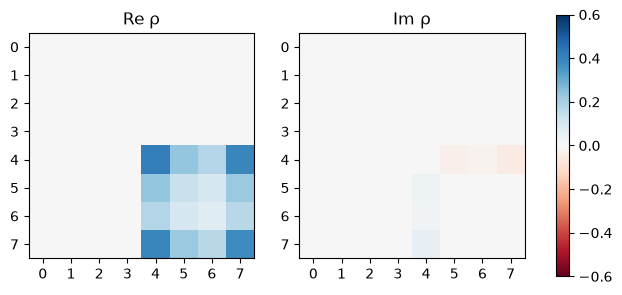

In [5]:
rho = states.random_canonical_state('GHZ', rng)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
for a, part, t in zip(ax, (rho.real, rho.imag), ('Re ρ', 'Im ρ')):
    im = a.imshow(part, cmap='RdBu', vmin=-0.6, vmax=0.6); a.set_title(t)
    a.set_xticks(range(8)); a.set_yticks(range(8))
fig.colorbar(im, ax=ax); plt.show()